# Week 1.3 · Optimizers for Scientific Machine Learning with TensorFlow and Keras

[Open in Colab](https://colab.research.google.com/github/Ehsan-Roohi/FlowMLLab/blob/main/notebooks/week01_3/W1_3_Keras_Optimizers.ipynb)

**Start after:** Week 1, Notebook 02, *TensorFlow for AI in Fluids*, especially the sine-fit section. **Study time:** 45–60 minutes for the core lab, plus time for the research extension. Select a CPU runtime and run from the top in a fresh kernel. The notebook generates its own data.

You have already changed sample counts, network depth and activation. Here the first question is narrower: **what changes when you hold the network, initial weights and data fixed and swap the optimizer?**

1. Compare momentum, Adam and limited-memory Broyden–Fletcher–Goldfarb–Shanno (L-BFGS).
2. Account for rejected line-search trials and distinguish update count, gradient evaluations and elapsed time.
3. Use loss and error profiles to distinguish an unstable step, an inadequately sampled feature, and a network that struggles to represent it.
4. Explain why a low average error can hide a large local discrepancy.
5. Test the deep-cavity SOAP → self-scaled Broyden sequence against matched controls.

A standard Colab CPU runtime should already supply TensorFlow, NumPy, SciPy and Matplotlib. For a fresh local Python 3.12 environment, install them with:

    python -m pip install "tensorflow>=2.16,<2.22" "numpy>=2.0,<2.3" "scipy>=1.13,<1.16" matplotlib ipykernel

Then open this notebook in the matching Jupyter kernel.

In [1]:
import os
import sys
import warnings
from time import perf_counter

# Set before TensorFlow is imported.
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ["OPENBLAS_NUM_THREADS"] = "1"

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import scipy
from scipy.optimize import line_search, minimize
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import tensorflow as tf
from io import BytesIO
from IPython.display import Image, Markdown, display

tf.config.set_visible_devices([], "GPU")
tf.config.threading.set_inter_op_parallelism_threads(1)
tf.config.threading.set_intra_op_parallelism_threads(1)

DTYPE = tf.float64
SEED = 2026
METHODS = ("Momentum", "Adam", "L-BFGS", "Adam → L-BFGS")
COLORS = dict(zip(METHODS, ("#85610a", "#bd3840", "#00757e", "#2452a4")))
STYLES = dict(zip(METHODS, ("-.", "-", "--", ":")))
RESEARCH_METHODS = ("Adam", "Adam → L-BFGS", "SOAP", "Adam → SSB", "SOAP → SSB")
COLORS.update({"SOAP": "#725294", "Adam → SSB": "#c35c00", "SOAP → SSB": "#1d713e"})
STYLES.update({"SOAP": "-.", "Adam → SSB": "--", "SOAP → SSB": "-"})
plt.rcParams.update({"figure.dpi": 105, "axes.spines.top": False, "axes.spines.right": False})
def add_figure_key(figure, handles, columns):
    figure.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.93),
                  ncol=columns, frameon=False, fontsize=9)

def show_figure(figure):
    figure.canvas.draw()
    renderer = figure.canvas.get_renderer()
    for legend in figure.legends:
        legend_bounds = legend.get_window_extent(renderer)
        assert all(not legend_bounds.overlaps(ax.get_tightbbox(renderer)) for ax in figure.axes)
        title = figure._suptitle
        assert title is None or not legend_bounds.overlaps(title.get_window_extent(renderer))
    assert all(ax.get_legend() is None for ax in figure.axes)
    buffer = BytesIO()
    figure.savefig(buffer, format="png", dpi=120, bbox_inches="tight")
    plt.close(figure)
    display(Image(data=buffer.getvalue()))

print(f"Python {sys.version.split()[0]} | TensorFlow {tf.__version__} | SciPy {scipy.__version__}")
print("Visible devices:", [device.name for device in tf.config.get_visible_devices()])

Python 3.12.14 | TensorFlow 2.20.0 | SciPy 1.15.3
Visible devices: ['/physical_device:CPU:0']


## 1. Four profiles on the same interval

| Profile | What it challenges |
| --- | --- |
| sin(2πx) | The smooth baseline from Notebook 02 |
| x² sin(2πx) | The same oscillation with a changing amplitude |
| 0.65 sin(2πx) + 0.20 sin(8πx) + 0.08 cos(16πx) | Resolving short waves alongside a stronger long wave |
| 0.20 sin(2πx) + exp[−((x − 0.72)/0.035)²] | Resolving a narrow peak, like a localized load |

Training uses a grid including both endpoints. Validation and test use separate interleaved coordinates, so this measures **interpolation** in [0, 1]. For each target, compute the mean $\mu_{\mathrm{tr}}$ and standard deviation $\sigma_{\mathrm{tr}}$ using training targets only. Minimize mean squared error (MSE) on $z=(y-\mu_{\mathrm{tr}})/\sigma_{\mathrm{tr}}$. Undo the scaling before reporting errors on the original scale.

Validation diagnoses changes to the design and guides your choices. The held-out comparison is gated in Section 6. Decide which configuration to report before turning it on.

A sine fit is a useful control: the official PyTorch optimizer tutorial fits a cubic polynomial to sine. Our localized case tests spatial coverage; the multiscale case tests how well a smooth network resolves simultaneous frequencies. The research extension below adds a chirp, whose local frequency increases with position.

- [PyTorch optimizer tutorial](https://docs.pytorch.org/tutorials/beginner/examples_nn/polynomial_optim.html)
- [Tancik et al., Fourier Features (NeurIPS 2020)](https://proceedings.neurips.cc/paper/2020/hash/55053683268957697aa39fba6f231c68-Abstract.html)


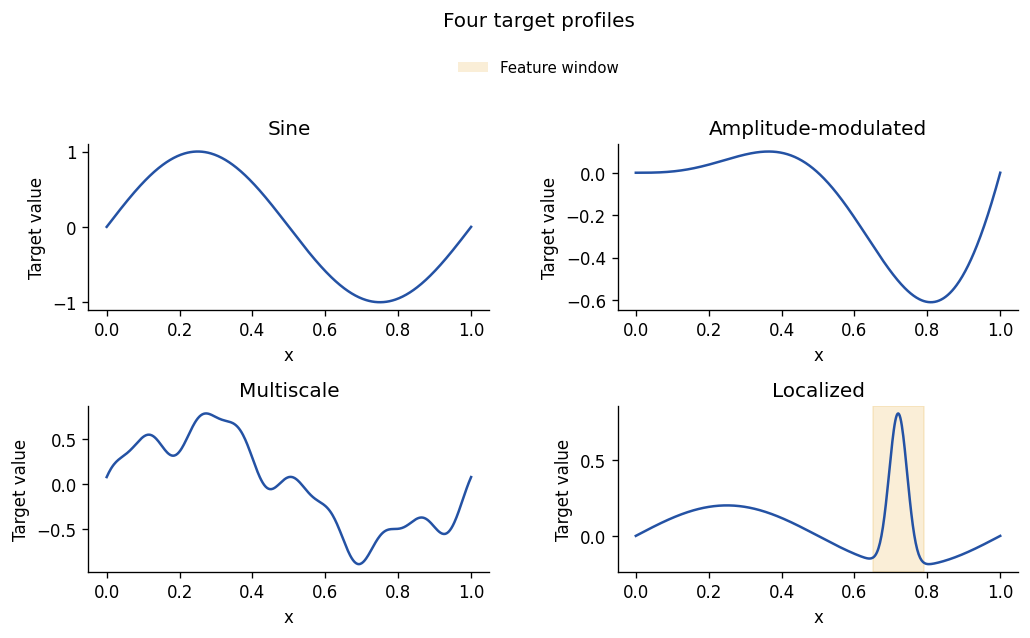

In [2]:
def sine(x):
    return np.sin(2 * np.pi * x)

TARGETS = {
    "Sine": sine,
    "Amplitude-modulated": lambda x: x**2 * sine(x),
    "Multiscale": lambda x: 0.65*sine(x) + 0.20*np.sin(8*np.pi*x) + 0.08*np.cos(16*np.pi*x),
    "Localized": lambda x: 0.20*sine(x) + np.exp(-((x - 0.72)/0.035)**2),
}
FEATURE = (0.65, 0.79)

def make_data(name, n_train=121, n_val=61, n_test=601, normalize=True):
    if min(n_train, n_val, n_test) < 2:
        raise ValueError("Use at least two points in each split.")
    # Each role uses an evenly spaced grid, with reproducibly different offsets.
    x_train = np.linspace(0, 1, n_train)[:, None]
    x_val = ((np.arange(n_val) + 0.31) / n_val)[:, None]
    x_test = ((np.arange(n_test) + 0.67) / n_test)[:, None]
    joined = np.sort(np.concatenate([x_train[:, 0], x_val[:, 0], x_test[:, 0]]))
    if np.min(np.diff(joined)) < 1e-12:
        raise ValueError("These point counts cause a split collision. Change one count.")
    y = TARGETS[name](x_train)
    mu, sigma = (float(y.mean()), float(y.std())) if normalize else (0.0, 1.0)
    if sigma < 1e-12:
        raise ValueError("Training targets are nearly constant. Use more sample points.")
    return {"x_train": x_train, "x_val": x_val, "x_test": x_test,
            "y_train": y, "y_val": TARGETS[name](x_val), "mu": mu, "sigma": sigma}

x_display = np.linspace(0, 1, 501)
fig, axes = plt.subplots(2, 2, figsize=(10, 5.4))
fig.subplots_adjust(top=0.78, bottom=0.12, hspace=0.58, wspace=0.32)
fig.suptitle("Four target profiles", y=0.985)
for ax, (name, target) in zip(axes.flat, TARGETS.items()):
    ax.plot(x_display, target(x_display), color="#2452a4")
    ax.set(xlabel="x", ylabel="Target value", title=name)
    if name == "Localized":
        ax.axvspan(*FEATURE, color="#e9b44c", alpha=0.22, label="Feature window")
add_figure_key(fig, [Patch(facecolor="#e9b44c", alpha=0.22, label="Feature window")], 1)
show_figure(fig)

## 2. Optimizer update rules

Let $\theta_k$ be the vector of all weights and biases before update $k$, $J(\theta)$ the full-training-set mean squared error, and $g_k=\nabla_\theta J(\theta_k)$ its gradient. The same $J$ and starting weights are used for every route on a given target.

**Momentum.** Carry some of the previous update in the velocity $v_k$, with $v_0=0$:

$$
v_{k+1}=\mu v_k-\eta g_k,\qquad \theta_{k+1}=\theta_k+v_{k+1}.
$$

$\eta=0.015$ is the default learning rate and $\mu=0.85$ is the retained fraction of the previous update. Consistent gradients build speed. Reversing gradients can produce overshoot.

**Adam.** Average the gradient and its elementwise square. The Keras update used here is

$$
m_{k+1}=\beta_1m_k+(1-\beta_1)g_k,\qquad
q_{k+1}=\beta_2q_k+(1-\beta_2)g_k^2,
$$

$$
\theta_{k+1}=\theta_k-
\eta\frac{\sqrt{1-\beta_2^{k+1}}}{1-\beta_1^{k+1}}
\frac{m_{k+1}}{\sqrt{q_{k+1}}+\epsilon}.
$$

$m_0=q_0=0$. Here $m$ is the moving mean, $q$ the moving mean square, $\beta_1=0.9$ and $\beta_2=0.999$ their decay rates, $\epsilon=10^{-7}$ a numerical safeguard, and $\eta=0.01$ the default learning rate. Squaring, square roots and division of parameter vectors act elementwise. The scalar factor corrects for zero initialization. This gives each parameter its own effective step scale.

**L-BFGS.** Use recent accepted parameter and gradient differences to approximate the inverse Hessian:

$$
d_k=-H_kg_k,\qquad \theta_{k+1}=\theta_k+\alpha_k d_k,\qquad
s_k=\theta_{k+1}-\theta_k,\qquad y_k=g_{k+1}-g_k.
$$

$H_k$ is the implicit inverse-Hessian approximation, $d_k$ the search direction, and $\alpha_k$ the step length chosen by line search. $s_k$ is the accepted parameter displacement and $y_k$ the gradient change on the same objective. Each retained pair carries curvature information. The underlying BFGS update uses $V_k=I-\rho_k s_k y_k^\top$ and $\rho_k=1/(y_k^\top s_k)$:

$$
H_{k+1}=V_k H_k V_k^\top+\rho_k s_k s_k^\top .
$$

$I$ denotes the identity matrix and $\top$ denotes transpose. L-BFGS represents the action of $H_k$ using a short history of pairs. The lab calls SciPy's L-BFGS-B without box bounds.

**Adam → L-BFGS.** Use the Adam rule for the first 270 joint evaluations, then use the L-BFGS rule starting from the last Adam weights. The hybrid shares the two rules above. The main experiment gives every route at most 600 joint calls to the training objective and gradient, including line-search trials. Curves show accepted states. Timing also includes the monitoring work during the timed run.

### Two additional methods used in Section 5

**SOAP.** For a dense weight matrix $W$, let $G=\nabla_W J$ and let $Q_L,Q_R$ be the orthogonal bases estimated from the moving averages of $GG^\top$ and $G^\top G$. Apply the Adam direction in those coordinates and rotate it back:

$$
\widetilde G=Q_L^\top GQ_R,\qquad
W_{\mathrm{new}}=W-\eta Q_L\widetilde UQ_R^\top .
$$

$\widetilde U$ is the bias-corrected Adam-style step per unit learning rate in the rotated coordinates. Here $\eta=0.005$. Bias vectors use Adam-style moments without rotation. SOAP uses its own numerical safeguard, $10^{-8}$. This allows adaptation along directions that combine several original weights.

**Self-scaled Broyden (SSB).** Use the quasi-Newton step above, with a dense update:

$$
z=H_k y_k,\qquad a=y_k^\top s_k,\qquad b=y_k^\top z,\qquad
u=\frac{s_k}{a}-\frac{z}{b},
$$

$$
H_{k+1}=\frac{1}{\tau_k}
\left(H_k-\frac{zz^\top}{b}+\phi_k b uu^\top\right)
+\frac{s_k s_k^\top}{a}.
$$

$z$ is the previous inverse-Hessian approximation applied to the gradient change, $a,b$ are positive curvature products, and $u$ is the correction direction. The self-scale $\tau_k>0$ and Broyden coefficient $\phi_k$ are calculated from the accepted step and curvature products in the implementation below. SSB uses a fixed objective for consecutive gradients. The research routes **Adam → SSB** and **SOAP → SSB** switch at joint call 240.

[Keras momentum](https://keras.io/api/optimizers/sgd/) · [Keras Adam](https://keras.io/api/optimizers/adam/) · [SciPy L-BFGS-B](https://docs.scipy.org/doc/scipy/reference/optimize.minimize-lbfgsb.html) · [SOAP](https://arxiv.org/abs/2409.11321) · [Self-scaled Broyden](https://arxiv.org/abs/2405.04230)


In [3]:
def make_model(widths, activation, seed):
    layers = [tf.keras.Input(shape=(1,), dtype=DTYPE)]
    for i, width in enumerate(widths):
        layers.append(tf.keras.layers.Dense(width, activation=activation, dtype=DTYPE,
            kernel_initializer=tf.keras.initializers.GlorotUniform(seed=seed+i)))
    layers.append(tf.keras.layers.Dense(1, dtype=DTYPE,
        kernel_initializer=tf.keras.initializers.GlorotUniform(seed=seed+len(widths))))
    return tf.keras.Sequential(layers)

def pack(arrays):
    return np.concatenate([np.asarray(a).ravel() for a in arrays])

def assign_flat(model, values):
    offset = 0
    for variable in model.trainable_variables:
        size = int(np.prod(variable.shape))
        variable.assign(values[offset:offset+size].reshape(variable.shape))
        offset += size
    assert offset == len(values)

class EvaluationBudgetReached(Exception):
    pass


class DenseLayerSOAP:
    """SOAP for dense kernels only. Bias vectors use ordinary Adam moments."""

    def __init__(self, parameters, rate, refresh=10):
        self.rate = rate
        self.refresh = refresh
        self.step = 0
        self.first = [np.zeros_like(p) for p in parameters]
        self.second = [np.zeros_like(p) for p in parameters]
        self.statistics = [
            [np.zeros((n, n)) for n in p.shape] if p.ndim == 2 else []
            for p in parameters
        ]
        self.bases = [None for _ in parameters]

    def update(self, parameters, gradients):
        beta1, beta2 = 0.9, 0.999
        new_parameters = []
        for i, (p, g) in enumerate(zip(parameters, gradients)):
            basis = self.bases[i]
            step = p
            if self.step:
                self.first[i] = beta1 * self.first[i] + (1 - beta1) * g
                if basis is None:
                    projected = g
                    first = self.first[i]
                else:
                    left, right = basis
                    projected = left.T @ g @ right
                    first = left.T @ self.first[i] @ right
                self.second[i] = beta2 * self.second[i] + (1 - beta2) * projected**2
                direction = first / (np.sqrt(self.second[i]) + 1e-8)
                if basis is not None:
                    direction = left @ direction @ right.T
                bias_correction = np.sqrt(1 - beta2**self.step) / (1 - beta1**self.step)
                step = p - self.rate * bias_correction * direction
            new_parameters.append(step)
            if g.ndim != 2:
                continue
            for axis, gram in enumerate((g @ g.T, g.T @ g)):
                self.statistics[i][axis] *= beta2
                self.statistics[i][axis] += (1 - beta2) * gram
            if basis is None:
                self.bases[i] = [np.linalg.eigh(gram)[1][:, ::-1] for gram in self.statistics[i]]
            elif self.step % self.refresh == 0:
                new_basis = []
                for axis, gram in enumerate(self.statistics[i]):
                    q = basis[axis]
                    order = np.argsort(np.sum(q * (gram @ q), axis=0))[::-1]
                    self.second[i] = np.take(self.second[i], order, axis=axis)
                    new_basis.append(np.linalg.qr(gram @ q[:, order])[0])
                self.bases[i] = new_basis
        self.step += 1
        return pack(new_parameters)


def self_scaled_broyden_update(H, s, y, g, alpha):
    """Dense inverse-Hessian form of the safeguarded self-scaled Broyden update."""
    with np.errstate(over="ignore", invalid="ignore", divide="ignore"):
        z = H @ y
        sy, yz, sg = y @ s, y @ z, s @ g
        if not (np.isfinite([sy, yz, sg]).all() and sy > 0 and yz > 0 and sg < 0):
            return H, "skipped"
        b = (-alpha * sg) / sy
        a = b * (yz / sy) - 1
        rho = min(1.0, (yz / sy) * (1 - np.sqrt(abs(a) / (1 + a)))) if 1 + a > 0 else 0
        if b > 0 and rho > 1e-14:
            lower = (rho - 1) / a if abs(a) > 1e-14 else 0.0
            theta = max(lower, min(1 / rho, (1 - b) / b))
            sigma = 1 + theta * a
            if sigma > 1e-14:
                bound = min(1.0, 1 / b)
                exponent = sigma**(1 / (1 - len(s)))
                tau = min(bound * exponent, sigma) if theta <= 0 else bound * min(exponent, 1 / theta)
                v = s / sy - z / yz
                candidate = (H - np.outer(z, z) / yz +
                             ((1 - theta) / sigma) * yz * np.outer(v, v)) / tau
                candidate += np.outer(s, s) / sy
                if valid_secant(candidate, s, y):
                    return candidate, "SSB"
        # BFGS is the retained fallback when the self-scaling formula fails its guards.
        candidate = (H - (np.outer(s, z) + np.outer(z, s)) / sy
                     + (1 + yz / sy) * np.outer(s, s) / sy)
        return (candidate, "BFGS fallback") if valid_secant(candidate, s, y) else (H, "skipped")


def valid_secant(matrix, s, y):
    return (np.isfinite(matrix).all()
            and np.linalg.norm(matrix @ y - s) <= 1e-6 * max(np.linalg.norm(s), 1e-30))


def self_scaled_broyden(evaluate, initial, accepted, trace):
    """Spend the same joint-call budget as other methods, including rejected trials."""
    x = initial.copy()
    loss, g = evaluate(x)
    H = np.eye(len(x))
    while np.linalg.norm(g, ord=np.inf) > 1e-9:
        direction = -(H @ g)
        if not np.isfinite(direction).all() or g @ direction >= 0:
            H = np.eye(len(x))
            trace["direction resets"] += 1
            direction = -g

        # SciPy requests f and grad separately. Reuse the joint result at the same trial.
        trial_x = x
        trial_loss, trial_g = loss, g

        def trial(w):
            nonlocal trial_x, trial_loss, trial_g
            if not np.array_equal(w, trial_x):
                trial_loss, trial_g = evaluate(w)
                trial_x = w.copy()
            return trial_loss, trial_g

        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", message=".*line search algorithm did not converge.*")
            alpha, *_ = line_search(lambda w: trial(w)[0], lambda w: trial(w)[1], x,
                                    direction, gfk=g, old_fval=loss, c1=1e-4, c2=0.9, maxiter=15)
        if alpha is None:
            return "No strong-Wolfe step found"
        s = alpha * direction
        next_x = x + s
        next_loss, next_g = trial(next_x)
        # Check the conditions explicitly. Some line-search stops return a trial alpha.
        if (not np.isfinite(next_loss) or not np.isfinite(next_g).all()
                or next_loss > loss + 1e-4 * (g @ s)
                or abs(next_g @ direction) > 0.9 * abs(g @ direction)):
            return "Rejected trial that did not satisfy strong Wolfe"
        accepted(next_x)
        H, status = self_scaled_broyden_update(H, s, next_g - g, g, alpha)
        trace[status] += 1
        x, loss, g = next_x, next_loss, next_g
    return "Gradient tolerance reached"



def run_fit(name, method, *, widths=(24, 24), activation="tanh", seed=SEED,
            n_train=121, n_val=61, n_test=601, normalize=True, budget=600,
            switch=270, adam_lr=0.01, momentum_lr=0.015, soap_lr=0.005, log_every=10):
    warmup, separator, refinement = method.partition(" → ")
    if not separator and warmup == "L-BFGS":
        warmup, refinement = "", "L-BFGS"
    if method not in set(METHODS + RESEARCH_METHODS) or budget < 2 or log_every < 1:
        raise ValueError("Use a listed method, budget >= 2, and log_every >= 1.")
    if separator and not 0 < switch < budget:
        raise ValueError("Set the hybrid switch strictly between 0 and budget.")
    data = make_data(name, n_train, n_val, n_test, normalize)
    model = make_model(widths, activation, seed)
    x_train = tf.constant(data["x_train"], dtype=DTYPE)
    z_train = tf.constant((data["y_train"] - data["mu"]) / data["sigma"], dtype=DTYPE)
    x_val = tf.constant(data["x_val"], dtype=DTYPE)
    z_val = tf.constant((data["y_val"] - data["mu"]) / data["sigma"], dtype=DTYPE)

    @tf.function
    def objective_gradient():
        with tf.GradientTape() as tape:
            loss = tf.reduce_mean(tf.square(model(x_train) - z_train))
        return loss, tape.gradient(loss, model.trainable_variables)

    @tf.function(input_signature=[tf.TensorSpec((None,), DTYPE)])
    def flat_objective(weights):
        offset = 0
        for variable in model.trainable_variables:
            size = int(np.prod(variable.shape))
            variable.assign(tf.reshape(weights[offset:offset + size], variable.shape))
            offset += size
        loss, gradients = objective_gradient()
        return loss, tf.concat([tf.reshape(g, (-1,)) for g in gradients], axis=0)

    @tf.function
    def monitor():
        train = tf.reduce_mean(tf.square(model(x_train) - z_train))
        val = tf.reduce_mean(tf.square(model(x_val) - z_val))
        return train, val

    initial_state = pack(model.get_weights())
    if refinement:
        flat_objective.get_concrete_function()
    if warmup == "SOAP":
        objective_gradient.get_concrete_function()
        soap = DenseLayerSOAP(model.get_weights(), soap_lr)
    elif warmup:
        if warmup == "Momentum":
            optimizer = tf.keras.optimizers.SGD(learning_rate=momentum_lr, momentum=0.85)
        else:
            optimizer = tf.keras.optimizers.Adam(learning_rate=adam_lr)
        optimizer.build(model.trainable_variables)

        @tf.function
        def first_order_step():
            loss, gradients = objective_gradient()
            optimizer.apply_gradients(zip(gradients, model.trainable_variables))
            train, val = monitor()
            weights = tf.concat([tf.reshape(w, (-1,)) for w in model.trainable_variables], 0)
            finite = tf.reduce_all(tf.math.is_finite(tf.stack((loss, train, val))))
            finite &= tf.reduce_all(tf.math.is_finite(weights))
            for gradient in gradients:
                finite &= tf.reduce_all(tf.math.is_finite(gradient))
            return weights, finite

        first_order_step.get_concrete_function()
    monitor()  # Trace the forward-only diagnostics.
    calls = 0
    updates = 0
    switch_call = None
    last_state = initial_state.copy()
    stop = "Evaluation budget reached"
    history = []
    started = perf_counter()

    def record():
        train, val = monitor()
        row = (calls, updates, perf_counter() - started, float(train), float(val))
        if history and history[-1][:2] == row[:2]:
            return
        history.append(row)

    trace = dict.fromkeys(("SSB", "BFGS fallback", "skipped", "direction resets"), 0)
    record()
    if warmup:
        phase_budget = switch if separator else budget
        for _ in range(phase_budget):
            calls += 1
            if warmup == "SOAP":
                loss, gradients = objective_gradient()
                grads = [g.numpy() for g in gradients]
                if not np.isfinite(float(loss)) or not np.isfinite(pack(grads)).all():
                    stop = "Non-finite SOAP objective or gradient"
                    break
                candidate = soap.update(model.get_weights(), grads)
                assign_flat(model, candidate)
                finite = np.isfinite(candidate).all() and all(np.isfinite(float(m)) for m in monitor())
            else:
                candidate, finite = first_order_step()
                candidate, finite = candidate.numpy(), bool(finite)
            if not finite:
                assign_flat(model, last_state)
                stop = "Non-finite update; restored last finite weights"
                break
            if warmup == "SOAP" and calls == 1:
                continue  # The first call initializes the SOAP basis without changing weights.
            last_state = candidate
            updates += 1
            if updates % log_every == 0:
                record()
        record()

    if refinement and (not warmup or (calls == switch and stop == "Evaluation budget reached")):
        switch_call = calls if warmup else None

        def scipy_objective(values):
            nonlocal calls
            if calls >= budget:
                raise EvaluationBudgetReached
            loss, gradients = flat_objective(tf.convert_to_tensor(values, dtype=DTYPE))
            calls += 1
            return float(loss), gradients.numpy()

        def accepted(values):
            nonlocal updates, last_state
            updates += 1
            last_state = values.copy()
            if updates % log_every == 0:
                assign_flat(model, last_state)
                record()

        try:
            if refinement == "SSB":
                stop = self_scaled_broyden(scipy_objective, last_state, accepted, trace)
            else:
                result = minimize(scipy_objective, last_state, jac=True, method="L-BFGS-B",
                                  callback=accepted, options={"maxiter": budget, "maxls": 35,
                                                             "ftol": 1e-14, "gtol": 1e-9})
                if np.isfinite(result.fun) and np.isfinite(result.x).all():
                    last_state = result.x.copy()
                stop = str(result.message)
        except EvaluationBudgetReached:
            pass
        assign_flat(model, last_state)
        record()

    assert calls <= budget
    return {"model": model, "data": data, "initial": initial_state, "history": np.array(history),
            "calls": calls, "updates": updates, "switch": switch_call,
            "seconds": perf_counter() - started, "stop": stop, "trace": trace}

def compare(name, **settings):
    results = {method: run_fit(name, method, **settings) for method in METHODS}
    first = results[METHODS[0]]["initial"]
    assert all(np.array_equal(result["initial"], first) for result in results.values())
    adam, hybrid = results["Adam"], results["Adam → L-BFGS"]
    boundary = hybrid["switch"]
    if boundary is not None:
        common = np.intersect1d(adam["history"][:, 0], hybrid["history"][hybrid["history"][:, 0] <= boundary, 0])
        np.testing.assert_allclose(adam["history"][np.isin(adam["history"][:, 0], common), 3:],
                                   hybrid["history"][np.isin(hybrid["history"][:, 0], common), 3:], rtol=1e-7, atol=1e-10)
    return results

def predict(result, x):
    data = result["data"]
    return data["mu"] + data["sigma"] * result["model"](x).numpy().ravel()

def rmse(error):
    return np.sqrt(np.mean(np.asarray(error)**2))

## 3. Read the comparison in three views

Run a baseline and a hard target first. The table shows optimizer cost and **validation** error in the original units. Compare training MSE against evaluation count and validation MSE against time. Section 4 puts training and validation on the same update axis. Then look at the validation profiles, including signed error ŷ − y. Markers identify the actual evaluation points. On the localized target, the shaded interval is the region in which you should also report error separately.

Set **TRAIN_POINTS**, **VAL_POINTS**, **WIDTHS**, **ACTIVATION**, **NORMALIZE**, **BUDGET** or **ADAM_LR** in the control cell below. Change one at a time. If you lower **BUDGET**, lower **SWITCH** too.
For each target, compare training MSE at the same number of joint evaluations, validation MSE at the same elapsed time, and the final signed error at the same location. A method can reduce training loss rapidly and still miss a feature on the validation grid. L-BFGS uses gradient differences to estimate useful rescalings in parameter space. Full-batch Adam adapts a separate step scale for each parameter, while momentum smooths gradient directions. The curves are evidence about this setup. Change one factor at a time before attributing a result to curvature, the learning rate, or model capacity.


**Sine**

| Route | Joint calls | Accepted updates | Seconds | Validation RMSE | Regional RMSE | Stop |
| --- | ---: | ---: | ---: | ---: | ---: | --- |
| Momentum | 600 | 600 | 1.469 | 0.1487 | — | Evaluation budget reached |
| Adam | 600 | 600 | 2.293 | 0.01314 | — | Evaluation budget reached |
| L-BFGS | 600 | 504 | 2.387 | 0.0006814 | — | Evaluation budget reached |
| Adam → L-BFGS | 600 | 558 | 2.027 | 0.001661 | — | Evaluation budget reached |

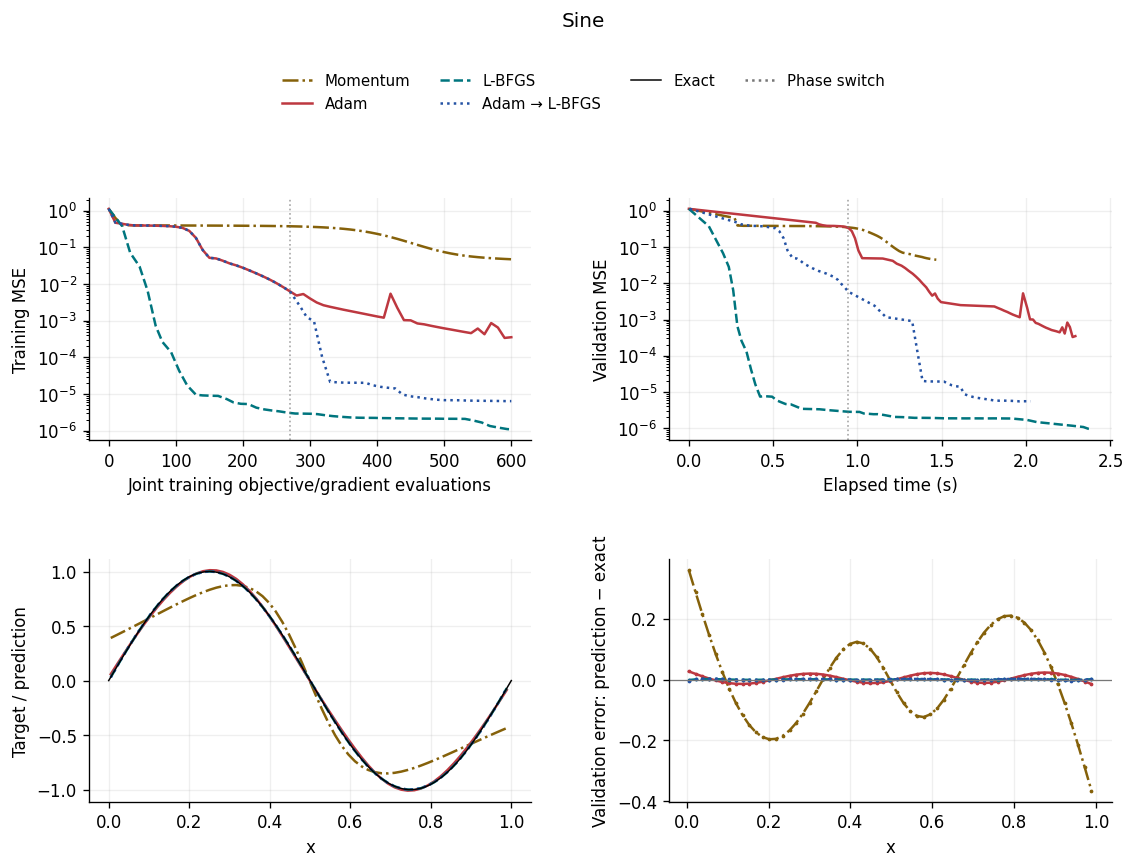

**Amplitude-modulated**

| Route | Joint calls | Accepted updates | Seconds | Validation RMSE | Regional RMSE | Stop |
| --- | ---: | ---: | ---: | ---: | ---: | --- |
| Momentum | 600 | 600 | 0.945 | 0.07871 | — | Evaluation budget reached |
| Adam | 600 | 600 | 1.087 | 0.005366 | — | Evaluation budget reached |
| L-BFGS | 600 | 507 | 1.869 | 0.000163 | — | Evaluation budget reached |
| Adam → L-BFGS | 600 | 559 | 1.573 | 0.001961 | — | Evaluation budget reached |

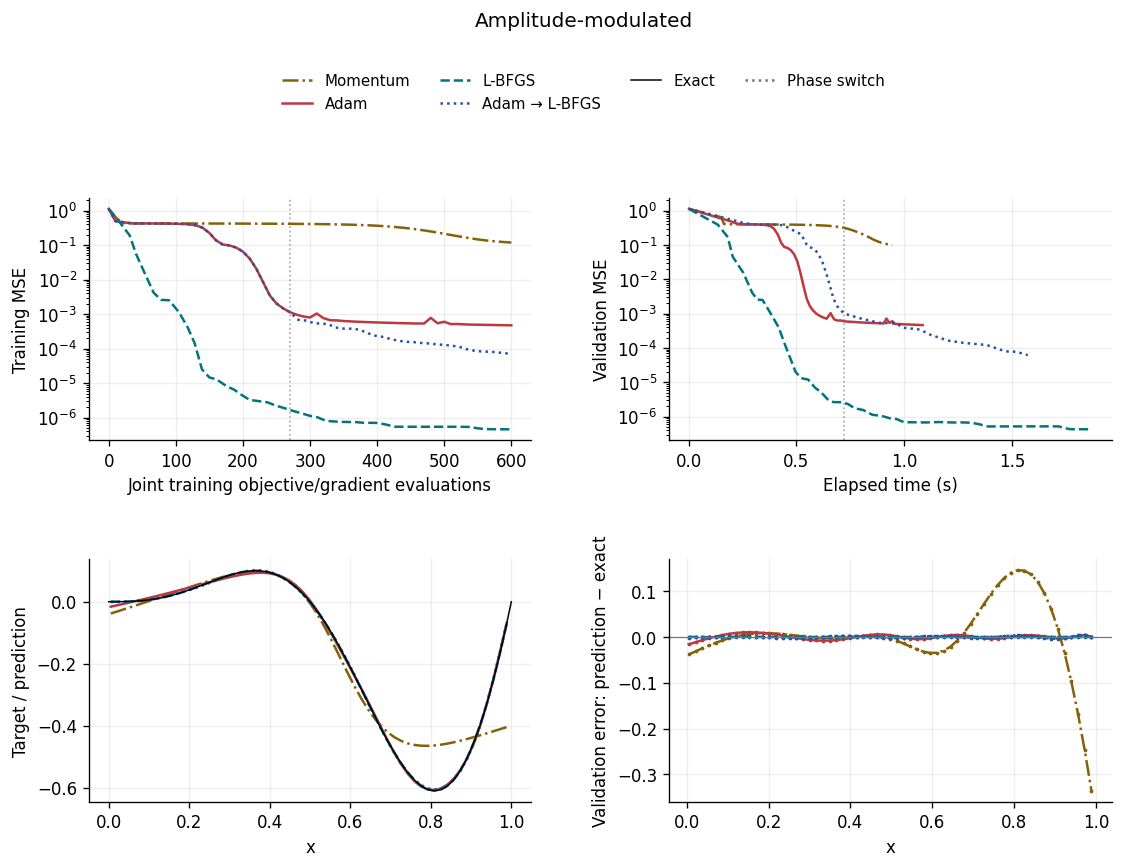

**Multiscale**

| Route | Joint calls | Accepted updates | Seconds | Validation RMSE | Regional RMSE | Stop |
| --- | ---: | ---: | ---: | ---: | ---: | --- |
| Momentum | 600 | 600 | 1.122 | 0.1633 | — | Evaluation budget reached |
| Adam | 600 | 600 | 1.487 | 0.09314 | — | Evaluation budget reached |
| L-BFGS | 600 | 511 | 1.640 | 0.02884 | — | Evaluation budget reached |
| Adam → L-BFGS | 600 | 559 | 2.245 | 0.06437 | — | Evaluation budget reached |

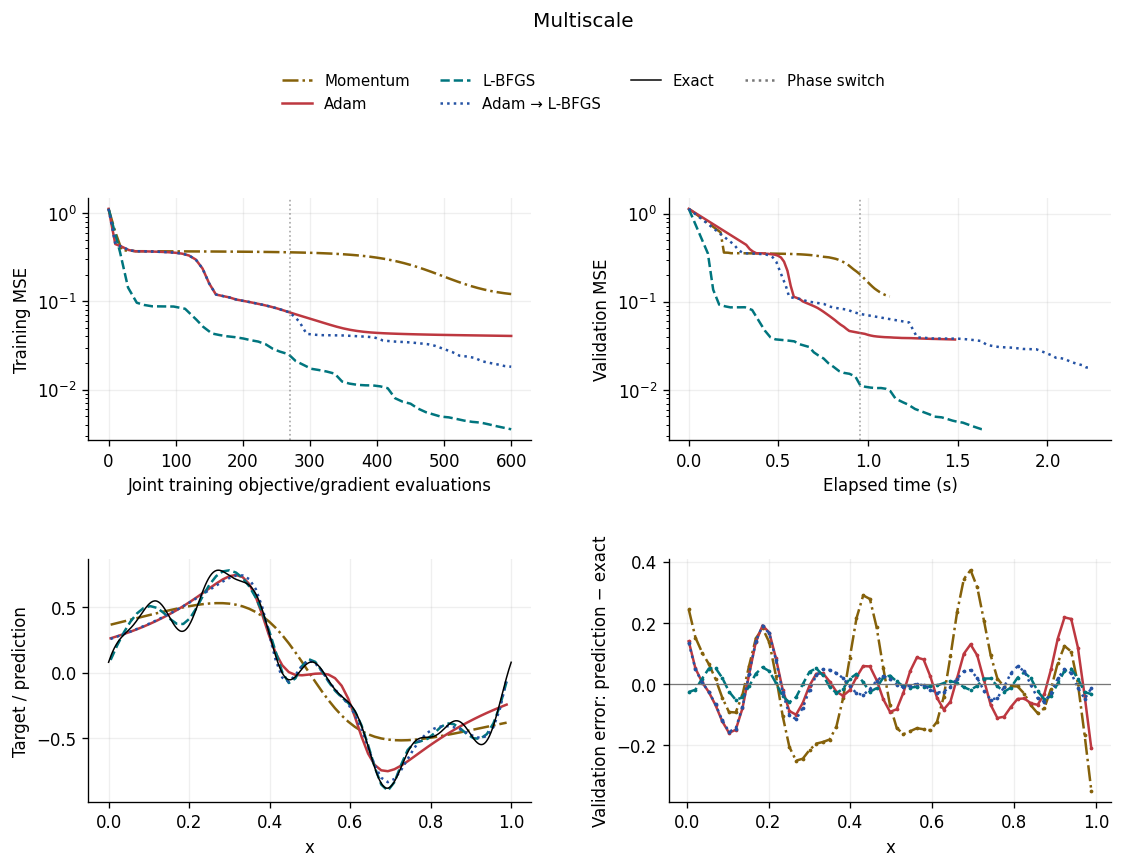

**Localized**

| Route | Joint calls | Accepted updates | Seconds | Validation RMSE | Peak window RMSE | Stop |
| --- | ---: | ---: | ---: | ---: | ---: | --- |
| Momentum | 600 | 600 | 1.147 | 0.1788 | 0.4245 | Evaluation budget reached |
| Adam | 600 | 600 | 1.360 | 0.007715 | 0.01614 | Evaluation budget reached |
| L-BFGS | 600 | 540 | 2.695 | 0.004568 | 0.0106 | Evaluation budget reached |
| Adam → L-BFGS | 600 | 562 | 1.641 | 0.00134 | 0.002389 | Evaluation budget reached |

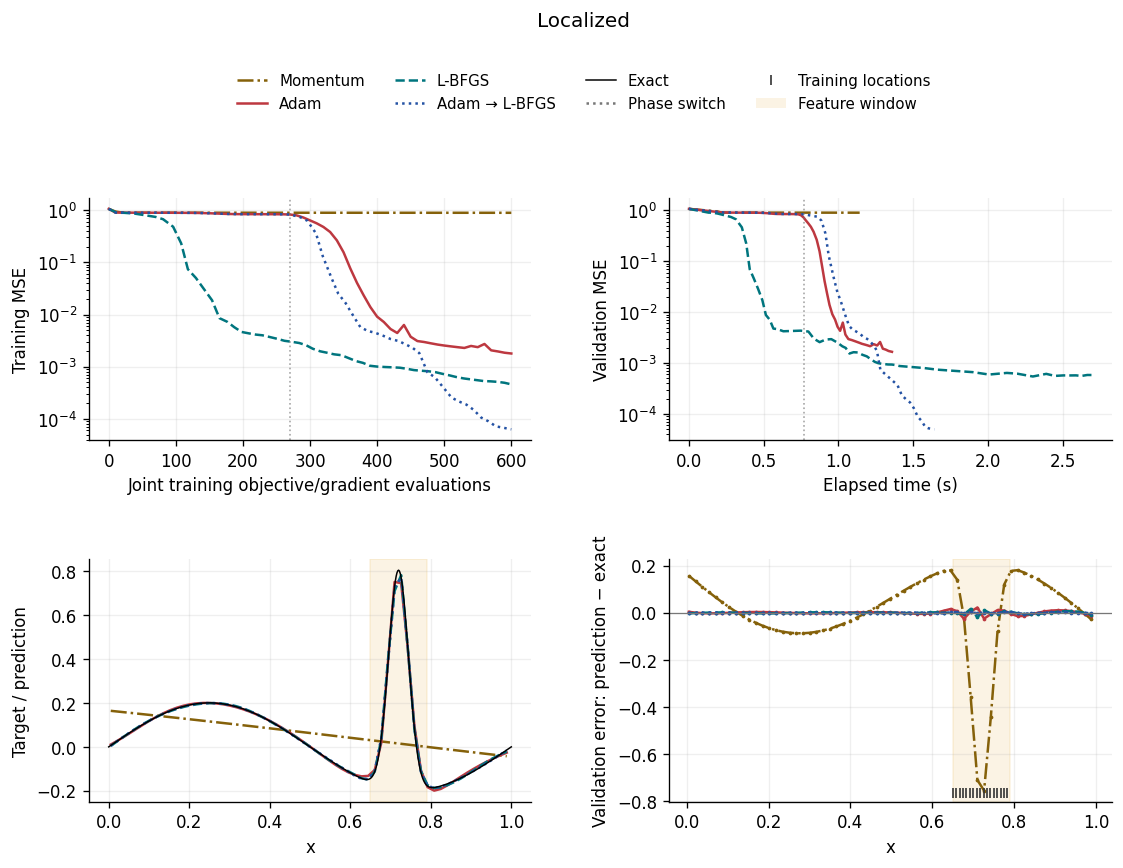

In [4]:
CASES = ("Sine", "Amplitude-modulated", "Multiscale", "Localized")  # Choose a subset for a shorter run.
TRAIN_POINTS, VAL_POINTS = 121, 61
WIDTHS, ACTIVATION = (24, 24), "tanh"
NORMALIZE = True
BUDGET, SWITCH = 600, 270
ADAM_LR, MOMENTUM_LR = 0.01, 0.015
SETTINGS = dict(widths=WIDTHS, activation=ACTIVATION, n_train=TRAIN_POINTS,
                n_val=VAL_POINTS, normalize=NORMALIZE, seed=SEED, budget=BUDGET,
                switch=SWITCH, adam_lr=ADAM_LR, momentum_lr=MOMENTUM_LR)

def cost_table(name, results):
    focus = "Peak window RMSE" if name == "Localized" else "Final quarter RMSE" if name == "Chirp" else "Regional RMSE"
    rows = [f"| Route | Joint calls | Accepted updates | Seconds | Validation RMSE | {focus} | Stop |",
            "| --- | ---: | ---: | ---: | ---: | ---: | --- |"]
    for method, result in results.items():
        data = result["data"]
        error = predict(result, data["x_val"]) - data["y_val"].ravel()
        x = data["x_val"].ravel()
        in_window = (x >= FEATURE[0]) & (x <= FEATURE[1])
        if name == "Chirp":
            in_window = x >= 0.75
        local = f"{rmse(error[in_window]):.4g}" if name in ("Localized", "Chirp") and in_window.any() else "—"
        rows.append(f"| {method} | {result['calls']} | {result['updates']} | "
                    f"{result['seconds']:.3f} | {rmse(error):.4g} | {local} | {result['stop']} |")
    display(Markdown(f"**{name}**\n\n" + "\n".join(rows)))

def plot_comparison(name, results, title=None):
    fig, axes = plt.subplots(2, 2, figsize=(11, 7.4))
    fig.subplots_adjust(top=0.775, bottom=0.095, hspace=0.49, wspace=0.31)
    for method, result in results.items():
        h = result["history"]
        for axis, x_column, loss_column in ((axes[0, 0], 0, 3), (axes[0, 1], 2, 4)):
            axis.semilogy(h[:, x_column], np.maximum(h[:, loss_column], 1e-30),
                          label=method, color=COLORS[method], linestyle=STYLES[method])
            if result["switch"] is not None:
                switch_row = h[np.flatnonzero(h[:, 0] == result["switch"])[0]]
                switch_color = "#777777" if title is None else COLORS[method]
                axis.axvline(switch_row[x_column], color=switch_color, linestyle=":", linewidth=1, alpha=0.65)
        x = result["data"]["x_val"]
        prediction = predict(result, x)
        target = result["data"]["y_val"].ravel()
        axes[1, 0].plot(x, prediction, color=COLORS[method], linestyle=STYLES[method], label=method)
        axes[1, 1].plot(x, prediction - target, color=COLORS[method],
                       linestyle=STYLES[method], marker=".", markersize=2.5, label=method)
    axes[0, 0].set(xlabel="Joint training objective/gradient evaluations", ylabel="Training MSE")
    axes[0, 1].set(xlabel="Elapsed time (s)", ylabel="Validation MSE")
    axes[1, 0].plot(x_display, TARGETS[name](x_display), color="black", linewidth=0.9, label="Exact")
    axes[1, 0].set(xlabel="x", ylabel="Target / prediction")
    handles, _ = axes[1, 0].get_legend_handles_labels()
    if any(result["switch"] is not None for result in results.values()):
        handles.append(Line2D([], [], color="#777777", linestyle=":", label="Phase switch"))
    axes[1, 1].set(xlabel="x", ylabel="Validation error: prediction − exact")
    axes[1, 1].axhline(0, color="#777777", linewidth=0.75)
    if name == "Localized":
        x_train = results[METHODS[0]]["data"]["x_train"].ravel()
        inside = (x_train >= FEATURE[0]) & (x_train <= FEATURE[1])
        axes[1, 1].plot(x_train[inside], np.full(np.count_nonzero(inside), 0.035),
                        "|", color="#333333", markersize=6, transform=axes[1, 1].get_xaxis_transform(),
                        label="Training locations in window")
        handles.extend([
            Line2D([], [], color="#333333", marker="|", linestyle="", label="Training locations"),
            Patch(facecolor="#e9b44c", alpha=0.15, label="Feature window"),
        ])
        for ax in axes[1, :]:
            ax.axvspan(*FEATURE, color="#e9b44c", alpha=0.15, zorder=0)
    for ax in axes.flat:
        ax.grid(alpha=0.2)
    fig.suptitle(title or name, y=0.985)
    add_figure_key(fig, handles, 3 if len(handles) > 8 else 4)
    show_figure(fig)

RESULTS = {}
for case in CASES:
    RESULTS[case] = compare(case, **SETTINGS)
    cost_table(case, RESULTS[case])
    plot_comparison(case, RESULTS[case])

## 4. Make an oversized update and diagnose it

Restart Adam with the **same weights and points** at two learning rates. We record fixed training and validation losses after each accepted update. If both curves jump together, the update moved the model to a worse part of the loss surface in this controlled experiment. If only an online minibatch log jumps in another notebook, first check whether you changed which points were measured. Validation may also drift while training improves. Those are different observations.

Can you reproduce a spike at a less extreme learning rate? Check where it first occurs. An occasional increase does not by itself establish divergence.

Adam lr=0.01: largest consecutive train-loss ratio 1.04 at update 15.
Adam lr=0.35: largest consecutive train-loss ratio 18.77 at update 1.


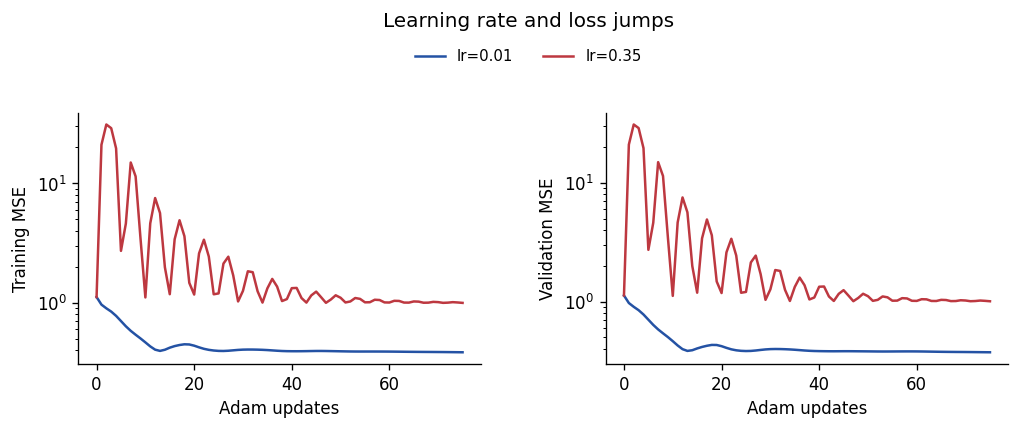

In [5]:
DIAGNOSTIC_RATES = (0.01, 0.35)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
fig.subplots_adjust(top=0.75, bottom=0.17, wspace=0.31)
fig.suptitle("Learning rate and loss jumps", y=0.985)
for rate, color in zip(DIAGNOSTIC_RATES, ("#2452a4", "#bd3840")):
    run = run_fit("Sine", "Adam", budget=75, adam_lr=rate, log_every=1)
    h = run["history"]
    if len(h) < 2:
        print(f"Adam lr={rate:g}: no accepted update to diagnose.")
        continue
    rise = h[1:, 3] / np.maximum(h[:-1, 3], 1e-30)
    idx = int(np.argmax(rise))
    print(f"Adam lr={rate:g}: largest consecutive train-loss ratio {rise[idx]:.2f} "
          f"at update {int(h[idx+1, 1])}.")
    for axis, column in zip(axes, (3, 4)):
        axis.semilogy(h[:, 1], np.maximum(h[:, column], 1e-30), color=color, label=f"lr={rate:g}")
for axis, label in zip(axes, ("Training MSE", "Validation MSE")):
    axis.set(xlabel="Adam updates", ylabel=label)
add_figure_key(fig, axes[0].get_lines(), 2)
show_figure(fig)

### A controlled replay of the scaling problem

A large offset can make a network spend its early updates learning the overall level while missing the variation of interest. Fit the manufactured target below with and without target scaling. Keep the initialization, optimizer, points and gradient budget fixed. Inspect the validation error in the **same original units**. This example is independent of any student's data.

Raw targets: original-scale validation RMSE = 983.7
Train-only scaling: original-scale validation RMSE = 4.35


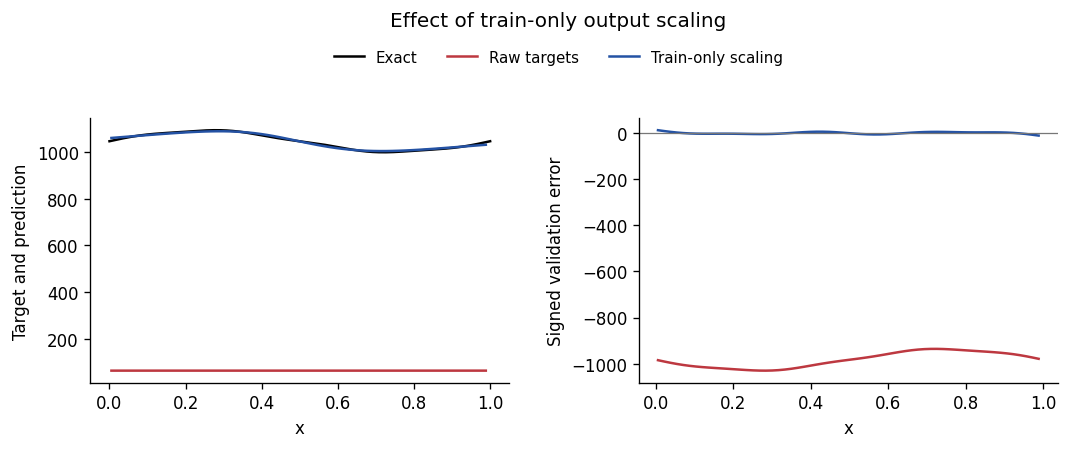

In [6]:
from matplotlib.ticker import ScalarFormatter

# A modest fluctuation riding on a much larger baseline.
TARGETS["Large-offset signal"] = lambda x: 1000 + 46*(1 + np.sin(2*np.pi*x)) + 3*np.sin(8*np.pi*x)
fig, axes = plt.subplots(1, 2, figsize=(10.4, 3.8))
fig.subplots_adjust(top=0.75, bottom=0.17, wspace=0.31)
fig.suptitle("Effect of train-only output scaling", y=0.985)
target = TARGETS["Large-offset signal"]
axes[0].plot(x_display, target(x_display), color="black", label="Exact")
for normalized, color in ((False, "#bd3840"), (True, "#2452a4")):
    scaled = run_fit("Large-offset signal", "Adam", normalize=normalized, budget=220)
    x = scaled["data"]["x_val"]
    actual = target(x).ravel()
    fitted = predict(scaled, x)
    caption = "Train-only scaling" if normalized else "Raw targets"
    print(f"{caption}: original-scale validation RMSE = {rmse(fitted - actual):.4g}")
    axes[0].plot(x, fitted, color=color, label=caption)
    axes[1].plot(x, fitted - actual, color=color, label=caption)
axes[0].yaxis.set_major_formatter(ScalarFormatter(useOffset=False))
axes[0].set(xlabel="x", ylabel="Target and prediction")
axes[1].axhline(0, color="#777777", linewidth=0.75)
axes[1].set(xlabel="x", ylabel="Signed validation error")
add_figure_key(fig, axes[0].get_lines(), 3)
show_figure(fig)

## 5. Test the deep-cavity optimizer sequence on a chirp

The [Roohi–McDevitt deep-cavity study](https://arxiv.org/html/2610.38814v2#S3.SS4.SSS1) used **SOAP → self-scaled Broyden (SSB)**. SOAP applies Adam-style updates in an estimated rotated basis. SSB uses consecutive gradient differences on a fixed objective and a line search. This CPU lab implements dense-layer SOAP and the dense inverse-Hessian form of SSB with a checked strong-Wolfe search. The cavity calculation used regional resampling during SOAP and a memory-efficient generator representation for SSB. Here both stages use the same fixed regression data; the lab tests the optimizer sequence with a different objective and implementation.

The instantaneous frequency of sin(2π(2x + 10x²)) rises from 2 to 22 cycles per unit interval. Use the error over x ≥ 0.75 as a second metric. A gain in whole-domain RMSE can come from fitting only the slower part of the signal. The comparisons use the same initialization, architecture, split, total evaluation limit and switch point. Compare **SOAP → SSB** with **Adam → SSB** for the warm-up choice, **SOAP** for continuing without a switch, and **Adam → L-BFGS** against **Adam → SSB** for the refinement choice. The warm-up learning rates are fixed in advance and listed in the code. Try multiple paired seeds before generalizing.

- [Vyas et al., SOAP](https://arxiv.org/abs/2409.11321) and the [authors’ reference implementation](https://github.com/nikhilvyas/SOAP)
- [Urbán et al., self-scaled Broyden](https://arxiv.org/abs/2405.04230)
- [Kiyani et al., optimizer benchmarks on PINN residuals](https://arxiv.org/abs/2501.16371)
- [SciPy optimization tutorial and Rosenbrock example](https://docs.scipy.org/doc/scipy/tutorial/optimize.html)


Adam → SSB: {'SSB': 166, 'BFGS fallback': 0, 'skipped': 0, 'direction resets': 0}
SOAP → SSB: {'SSB': 156, 'BFGS fallback': 0, 'skipped': 0, 'direction resets': 0}


**Chirp**

| Route | Joint calls | Accepted updates | Seconds | Validation RMSE | Final quarter RMSE | Stop |
| --- | ---: | ---: | ---: | ---: | ---: | --- |
| Adam | 600 | 600 | 0.964 | 0.5323 | 0.7294 | Evaluation budget reached |
| Adam → L-BFGS | 600 | 562 | 1.232 | 0.5206 | 0.7303 | Evaluation budget reached |
| SOAP | 600 | 599 | 4.288 | 0.5591 | 0.7282 | Evaluation budget reached |
| Adam → SSB | 600 | 406 | 1.855 | 0.491 | 0.7292 | Evaluation budget reached |
| SOAP → SSB | 600 | 395 | 4.001 | 0.4827 | 0.7304 | Evaluation budget reached |

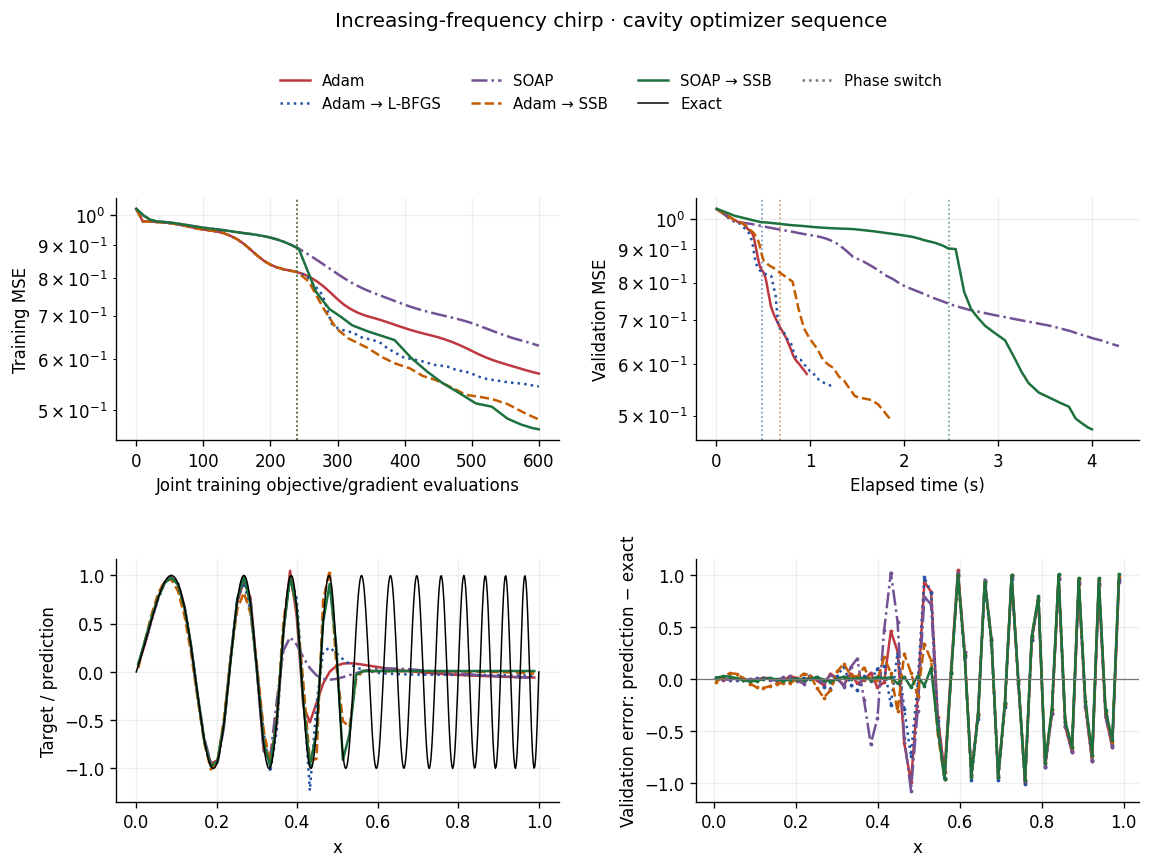

In [7]:
TARGETS["Chirp"] = lambda x: np.sin(2 * np.pi * (2*x + 10*x**2))
RESEARCH_SETTINGS = {**SETTINGS, "widths": (16, 16), "budget": 600, "switch": 240, "soap_lr": 0.005}
RESEARCH_RESULTS = {method: run_fit("Chirp", method, **RESEARCH_SETTINGS) for method in RESEARCH_METHODS}
for result in RESEARCH_RESULTS.values():
    np.testing.assert_array_equal(result["initial"], RESEARCH_RESULTS["Adam"]["initial"])
for baseline, hybrid in (("SOAP", "SOAP → SSB"), ("Adam", "Adam → SSB"), ("Adam", "Adam → L-BFGS")):
    h0 = RESEARCH_RESULTS[baseline]["history"]
    h1 = RESEARCH_RESULTS[hybrid]["history"]
    common = np.intersect1d(h0[:, 0], h1[h1[:, 0] <= RESEARCH_SETTINGS["switch"], 0])
    np.testing.assert_allclose(h0[np.isin(h0[:, 0], common), 3:], h1[np.isin(h1[:, 0], common), 3:],
                               rtol=1e-7, atol=1e-10)
cost_table("Chirp", RESEARCH_RESULTS)
for method, result in RESEARCH_RESULTS.items():
    if method.endswith("SSB"):
        print(f"{method}: {result['trace']}")
plot_comparison("Chirp", RESEARCH_RESULTS, title="Increasing-frequency chirp · cavity optimizer sequence")


## 6. Freeze a configuration, then use the test grid once

Before you change **REVEAL_TEST**, write down your selected target, optimizer, architecture, normalization choice and budget based on the validation plots. The table shows every predeclared route for those cases, using original-scale root mean square error (RMSE). In the localized window the maximum absolute error answers a different question from the whole-domain RMSE. Do not tune on these test numbers. Keep a new test protocol if you plan more changes after looking.

In [8]:
REVEAL_TEST = False
if REVEAL_TEST:
    for case, results in {**RESULTS, "Chirp": RESEARCH_RESULTS}.items():
        rows = ["| Route | Test RMSE | Max absolute error | Feature-window RMSE | Feature-window max |",
                "| --- | ---: | ---: | ---: | ---: |"]
        for method, result in results.items():
            x = result["data"]["x_test"]
            error = predict(result, x) - TARGETS[case](x).ravel()
            if case == "Localized":
                mask = (x[:, 0] >= FEATURE[0]) & (x[:, 0] <= FEATURE[1])
                local = error[mask]
                metrics = f"{rmse(local):.4g} | {np.max(np.abs(local)):.4g}" if local.size else "No points | No points"
            else:
                metrics = "— | —"
            rows.append(f"| {method} | {rmse(error):.4g} | {np.max(np.abs(error)):.4g} | {metrics} |")
        display(Markdown(f"**{case}**\n\n" + "\n".join(rows)))
else:
    print("Test scores hidden. Record your configuration before setting REVEAL_TEST = True.")

Test scores hidden. Record your configuration before setting REVEAL_TEST = True.


## 7. Engineering exercises

1. **Sampling and the narrow peak.** On Localized use 31, 61 and 121 training points. Keep the validation grid, optimizer and work limit fixed. Next keep training at 121 and compare 41, 61 and 101 validation points. Use the rug marks and report the number of training points inside the peak window, global validation RMSE and window RMSE. Explain whether the change altered the fit or just where you measured it.
2. **Network capacity.** On Multiscale compare widths (12,), (24, 24) and (32, 32, 32). Use the same split, optimizer, activation and budget. Report the trainable parameter count, joint calls, elapsed seconds, and RMSE. Double the budget for one width. Use the error profile to explain whether extra work or added capacity helped resolve the faster waves.
3. **Activation and derivatives.** On Sine compare tanh, ReLU and swish with the same architecture and optimizer. Report value and derivative RMSE in original units. Start with:

        fit = run_fit("Sine", "Adam", **SETTINGS)
        x = tf.constant(fit["data"]["x_val"], dtype=DTYPE)
        with tf.GradientTape() as tape:
            tape.watch(x)
            y = fit["data"]["mu"] + fit["data"]["sigma"] * fit["model"](x)
        derivative = tape.gradient(y, x).numpy().ravel()
        exact = 2 * np.pi * np.cos(2 * np.pi * x.numpy().ravel())
        print(rmse(derivative - exact))

   For the ReLU rerun replace `**SETTINGS` in the first line with `**{**SETTINGS, "activation": "relu"}`. Explain how the derivative diagnostic differs from a training loss and why activation matters when a physical residual uses second derivatives.
4. **Loss jump and scale.** Reproduce the two Adam rates in Section 4 and report the training and validation losses immediately before and after the largest jump. Rerun the large-offset fit with and without train-only scaling and report original-unit validation errors. Identify which parts of the experiment were held fixed.
5. **Switching cost.** On Sine and Localized test switches at calls 120, 270 and 420 under the same 600-call limit. Include Adam-only and L-BFGS-only controls. Check the matched Adam prefixes, choose using validation, then freeze your settings before revealing test scores. Report seconds as well as work counts.
6. **Cavity sequence.** Compare the chirp routes at seeds 2026, 2027 and 2028, with the same split at every seed. Report global and final-quarter validation RMSE, seconds, actual SSB updates and fallbacks. Change either network width or training density and rerun. Locate the unresolved oscillations in the signed error. Explain why lower regression loss does not establish more accurate cavity velocity or vorticity.

**Submit** a settings table, an error-and-cost table, a signed-error or prediction profile, a convergence plot and a short conclusion. Include frozen test metrics after selecting your settings on validation.

The [FlowMLLab Week 13 cavity PINN lab](https://github.com/Ehsan-Roohi/FlowMLLab/tree/main/weeks/week13) documents retained Adam → SSBroyden2 runs. In the [Roohi–McDevitt deep-cavity study](https://arxiv.org/html/2610.38814v2#S3.SS4.SSS1), regional collocation changes during the SOAP phase and is fixed for Broyden. Name the points and objective when comparing records from different phases. A loss computed on changing points answers a different question from a fixed-set diagnostic.
